# Tugas 2 Komputasi Multimedia: Transformasi Gambar, Image Compression, dan Watermarking

Nama: Arif Mufti Tharsa

NIM: 105224041

In [1]:
# Import library
import random
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymupdf  # untuk merender SVG menjadi bitmap
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

In [2]:
# Tetapkan seed dan path folder
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DAISEE_DIR = Path("../Data/DAiSEE")
GAMBAR_DIR = Path("../Data/Gambar_Kompresi")
AUG_DIR = Path("../Hasil/A_Augmentasi")
KOMP_DIR = Path("../Hasil/B_Kompresi")
WM_DIR = Path("../Hasil/C_Watermarking")
for d in (AUG_DIR, KOMP_DIR, WM_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Soal 1: Ekstrak Frame dan Ambil 10 Gambar Acak

Random seed yang dipakai: 42

In [3]:
# Cari video DAiSEE (.avi dan .mp4), pilih 10 video acak, lalu ambil 1 frame acak dari tiap video
random.seed(SEED)
video_files = sorted(list(DAISEE_DIR.rglob("*.avi")) + list(DAISEE_DIR.rglob("*.mp4")))
if not video_files:
    raise FileNotFoundError(f"Tidak ada video .avi/.mp4 di {DAISEE_DIR}")
print("Jumlah video (.avi + .mp4):", len(video_files))

(AUG_DIR / "0_Original").mkdir(parents=True, exist_ok=True)
frames = []
for i, video_path in enumerate(random.sample(video_files, 10), start=1):
    cap = cv2.VideoCapture(str(video_path))
    jumlah_frame = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if jumlah_frame <= 0:
        raise RuntimeError(f"Video tidak bisa dibuka: {video_path}")
    no_frame = random.randint(0, jumlah_frame - 1)
    cap.set(cv2.CAP_PROP_POS_FRAMES, no_frame)
    ok, frame_bgr = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError(f"Frame {no_frame} gagal dibaca dari {video_path}")
    frames.append(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    cv2.imwrite(str(AUG_DIR / "0_Original" / f"frame_{i:02d}.png"), frame_bgr)
    print(f"{i:2d}. {video_path.name} | frame {no_frame} dari {jumlah_frame}")

Jumlah video (.avi + .mp4): 9068
 1. 9988260222.avi | frame 16 dari 300
 2. 5100092021.avi | frame 15 dari 300
 3. 2100612002.avi | frame 47 dari 300
 4. 2100571049.avi | frame 111 dari 300
 5. 2100531017.avi | frame 119 dari 300
 6. 1100071071.avi | frame 258 dari 300
 7. 9403280273.avi | frame 13 dari 300


 8. 79940201930.mp4 | frame 287 dari 302
 9. 88265402120.mp4 | frame 101 dari 314
10. 4110211039.avi | frame 279 dari 300


# Soal 2: Implementasi 5 Teknik Augmentasi

In [4]:
# Definisi 5 teknik augmentasi
def aug_flip(img, kode=1):
    # Balik gambar (1 = kiri-kanan)
    return cv2.flip(img, kode)


def aug_rotasi(img, sudut=12.0):
    # Putar gambar di sekitar titik tengah, area kosong diisi pantulan tepi
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), sudut, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)


def aug_brightness_contrast(img, alpha=1.25, beta=30):
    # Hasil = alpha * piksel + beta (alpha = kontras, beta = kecerahan)
    return cv2.convertScaleAbs(img, alpha=alpha, beta=beta)


def aug_noise(img, sigma=18.0):
    # Tambah noise Gaussian, lalu batasi nilai ke 0-255
    noise = np.random.normal(0, sigma, img.shape)
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)


def aug_crop_scale(img, rasio=0.85):
    # Potong area tengah lalu perbesar kembali ke ukuran semula
    h, w = img.shape[:2]
    ch, cw = int(h * rasio), int(w * rasio)
    y, x = (h - ch) // 2, (w - cw) // 2
    return cv2.resize(img[y:y + ch, x:x + cw], (w, h))

In [5]:
# Terapkan tiap teknik ke 10 frame, simpan per teknik, dan hitung persen nilai 255 pada gambar asli dan hasil brightness
TEKNIK = {
    "1_Flip": aug_flip,
    "2_Rotasi": aug_rotasi,
    "3_Brightness-Contrast": aug_brightness_contrast,
    "4_Noise": aug_noise,
    "5_Crop-Scale": aug_crop_scale,
}
hasil_aug = {}
np.random.seed(SEED)
for nama_teknik, fungsi in TEKNIK.items():
    folder = AUG_DIR / nama_teknik
    folder.mkdir(parents=True, exist_ok=True)
    hasil_aug[nama_teknik] = []
    for i, frame in enumerate(frames, start=1):
        hasil = fungsi(frame)
        cv2.imwrite(str(folder / f"frame_{i:02d}.png"), cv2.cvtColor(hasil, cv2.COLOR_RGB2BGR))
        hasil_aug[nama_teknik].append(hasil)
        if nama_teknik == "3_Brightness-Contrast":
            asli = np.mean(frame == 255) * 100
            baru = np.mean(hasil == 255) * 100
            print(f"Frame {i:2d}: nilai 255 asli {asli:.2f}% | hasil {baru:.2f}% | selisih {baru - asli:.2f}%")

Frame  1: nilai 255 asli 0.00% | hasil 30.39% | selisih 30.39%
Frame  2: nilai 255 asli 0.02% | hasil 33.43% | selisih 33.41%
Frame  3: nilai 255 asli 0.01% | hasil 9.59% | selisih 9.58%
Frame  4: nilai 255 asli 0.02% | hasil 15.87% | selisih 15.84%
Frame  5: nilai 255 asli 0.02% | hasil 17.14% | selisih 17.13%
Frame  6: nilai 255 asli 0.59% | hasil 11.62% | selisih 11.03%
Frame  7: nilai 255 asli 0.00% | hasil 27.23% | selisih 27.22%
Frame  8: nilai 255 asli 0.00% | hasil 0.61% | selisih 0.61%
Frame  9: nilai 255 asli 0.00% | hasil 2.94% | selisih 2.94%
Frame 10: nilai 255 asli 0.00% | hasil 32.87% | selisih 32.87%


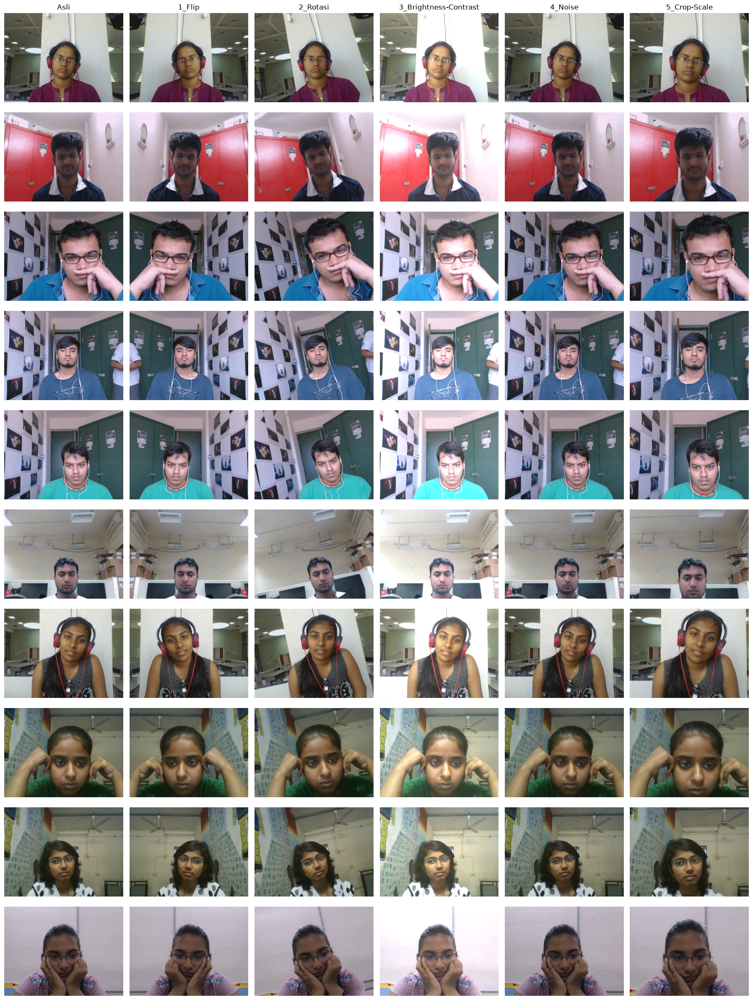

In [6]:
# Tampilkan grid: kolom 1 gambar asli, kolom 2-6 hasil tiap teknik
judul = ["Asli"] + list(TEKNIK.keys())
fig, axes = plt.subplots(10, 6, figsize=(18, 24))
for i in range(10):
    kolom = [frames[i]] + [hasil_aug[nama][i] for nama in TEKNIK]
    for j, img in enumerate(kolom):
        axes[i, j].imshow(img)
        axes[i, j].axis("off")
        if i == 0:
            axes[i, j].set_title(judul[j])
plt.tight_layout()
plt.savefig(AUG_DIR / "grid_augmentasi.png", dpi=100)
plt.show()

# Soal 4: Implementasi 3 Teknik Kompresi pada 4 Jenis Citra

In [7]:
# Muat 4 gambar input (SVG dirender dulu menjadi bitmap)
FILE_INPUT = {
    "BMP": GAMBAR_DIR / "input.bmp",
    "JPEG": GAMBAR_DIR / "input.jpg",
    "PNG": GAMBAR_DIR / "input.png",
    "SVG": GAMBAR_DIR / "input.svg",
}
citra = {}
for nama in ("BMP", "JPEG", "PNG"):
    path = FILE_INPUT[nama]
    citra[nama] = {"path": path, "arr": np.array(Image.open(path).convert("RGB"))}

# SVG dirender ke lebar 512 piksel, hasilnya disimpan sebagai BMP (baseline ukuran)
page = pymupdf.open(FILE_INPUT["SVG"])[0]
zoom = 512 / page.rect.width
pix = page.get_pixmap(matrix=pymupdf.Matrix(zoom, zoom), alpha=False)
arr_svg = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, 3)
path_svg_bmp = KOMP_DIR / "svg_render.bmp"
Image.fromarray(arr_svg).save(path_svg_bmp)
citra["SVG"] = {"path": path_svg_bmp, "arr": arr_svg}

In [8]:
# Fungsi: kompres satu citra dengan satu teknik lalu hitung metriknya
def kompres_dan_ukur(arr, path_asli, nama_citra, nama_teknik, fmt, params, path_out):
    # Simpan hasil kompresi dan ukur waktunya (milidetik)
    t0 = time.perf_counter()
    Image.fromarray(arr).save(path_out, format=fmt, **params)
    waktu_ms = (time.perf_counter() - t0) * 1000

    # Ukuran dalam KB, rasio kompresi, dan space saving
    ukuran_asli = Path(path_asli).stat().st_size / 1024
    ukuran_hasil = Path(path_out).stat().st_size / 1024
    rasio = ukuran_asli / ukuran_hasil
    saving = (1 - ukuran_hasil / ukuran_asli) * 100

    # Baca ulang hasilnya lalu bandingkan dengan citra asli
    rekon = np.array(Image.open(path_out).convert("RGB"))
    if np.array_equal(arr, rekon):
        nilai_psnr, nilai_ssim = float("inf"), 1.0
    else:
        nilai_psnr = psnr(arr, rekon, data_range=255)
        nilai_ssim = ssim(arr, rekon, data_range=255, channel_axis=2)

    baris = {
        "Citra": nama_citra,
        "Teknik": nama_teknik,
        "Ukuran Asli (KB)": ukuran_asli,
        "Ukuran Hasil (KB)": ukuran_hasil,
        "Rasio": rasio,
        "Space Saving (%)": saving,
        "PSNR (dB)": nilai_psnr,
        "SSIM": nilai_ssim,
        "Waktu (ms)": waktu_ms,
    }
    return baris, rekon

In [9]:
# Jalankan 3 teknik pada 4 citra, lalu tampilkan tabel hasil
TEKNIK_KOMPRESI = [
    ("DEFLATE (PNG)", "PNG", {"optimize": True}),
    ("JPEG (Q=50)", "JPEG", {"quality": 50}),
    ("WebP (Q=50)", "WEBP", {"quality": 50}),
]
rekonstruksi = {}
baris_tabel = []
for nama_citra, data in citra.items():
    for nama_teknik, fmt, params in TEKNIK_KOMPRESI:
        path_out = KOMP_DIR / f"{nama_citra}_{fmt}.{fmt.lower()}"
        baris, rekon = kompres_dan_ukur(data["arr"], data["path"], nama_citra, nama_teknik, fmt, params, path_out)
        baris_tabel.append(baris)
        rekonstruksi[(nama_citra, nama_teknik)] = rekon
df_kompresi = pd.DataFrame(baris_tabel).round(2)
df_kompresi["SSIM"] = [round(b["SSIM"], 4) for b in baris_tabel]
df_kompresi

,Citra,Teknik,Ukuran Asli (KB),Ukuran Hasil (KB),Rasio,Space Saving (%),PSNR (dB),SSIM,Waktu (ms)
0,BMP,DEFLATE (PNG),586.05,241.82,2.42,58.74,inf,1.0000,29.95
1,BMP,JPEG (Q=50),586.05,25.62,22.88,95.63,33.45,0.9466,0.86
2,BMP,WebP (Q=50),586.05,16.44,35.65,97.20,33.41,0.9167,69.14
3,JPEG,DEFLATE (PNG),155.78,1341.67,0.12,-761.24,inf,1.0000,116.46
4,JPEG,JPEG (Q=50),155.78,137.04,1.14,12.03,31.56,0.9651,2.43
5,JPEG,WebP (Q=50),155.78,123.81,1.26,20.52,32.37,0.9583,91.80
6,PNG,DEFLATE (PNG),2155.47,1919.87,1.12,10.93,inf,1.0000,99.74
7,PNG,JPEG (Q=50),2155.47,180.83,11.92,91.61,27.40,0.9261,3.15
8,PNG,WebP (Q=50),2155.47,196.26,10.98,90.89,30.72,0.9604,116.60
9,SVG,DEFLATE (PNG),768.05,15.04,51.05,98.04,inf,1.0000,13.49


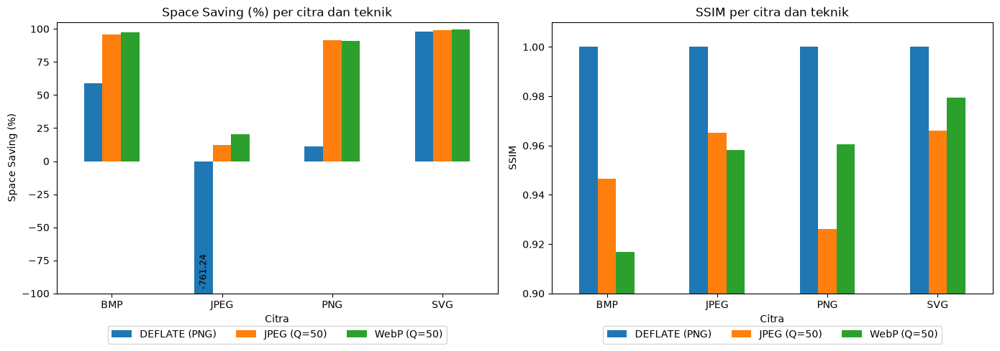

In [10]:
# Grafik batang: space saving (%) dan SSIM per citra dan teknik
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, kolom in zip(axes, ["Space Saving (%)", "SSIM"]):
    df_kompresi.pivot(index="Citra", columns="Teknik", values=kolom).plot(kind="bar", ax=ax, rot=0)
    ax.set_title(f"{kolom} per citra dan teknik")
    ax.set_ylabel(kolom)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
axes[0].set_ylim(-100, 105)
axes[1].set_ylim(0.9, 1.01)

# Bar Space Saving yang terpotong (di bawah -100) diberi anotasi nilainya
for bar in axes[0].patches:
    if bar.get_height() < -100:
        axes[0].text(bar.get_x() + bar.get_width() / 2, -97, f"{bar.get_height():.2f}",
                     ha="center", va="bottom", rotation=90, fontsize=9)
plt.tight_layout()
plt.savefig(KOMP_DIR / "grafik_kompresi.png", dpi=100, bbox_inches="tight")
plt.show()

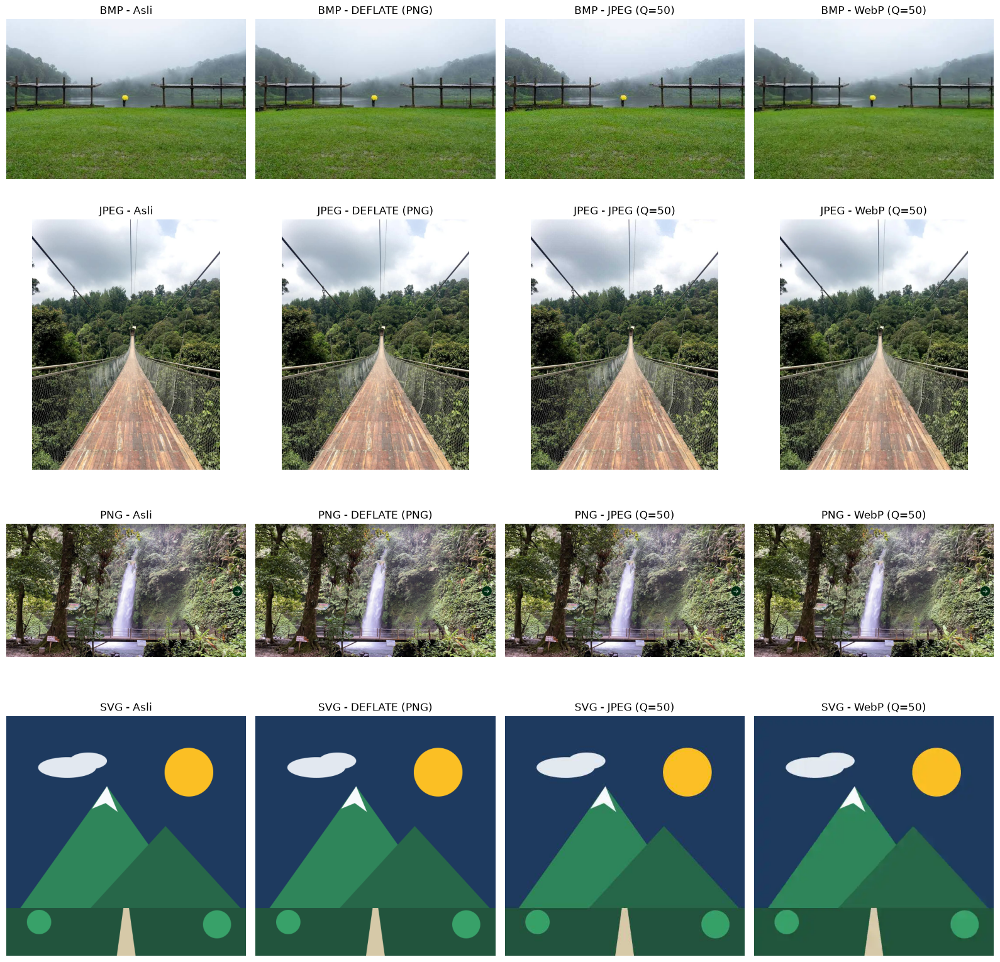

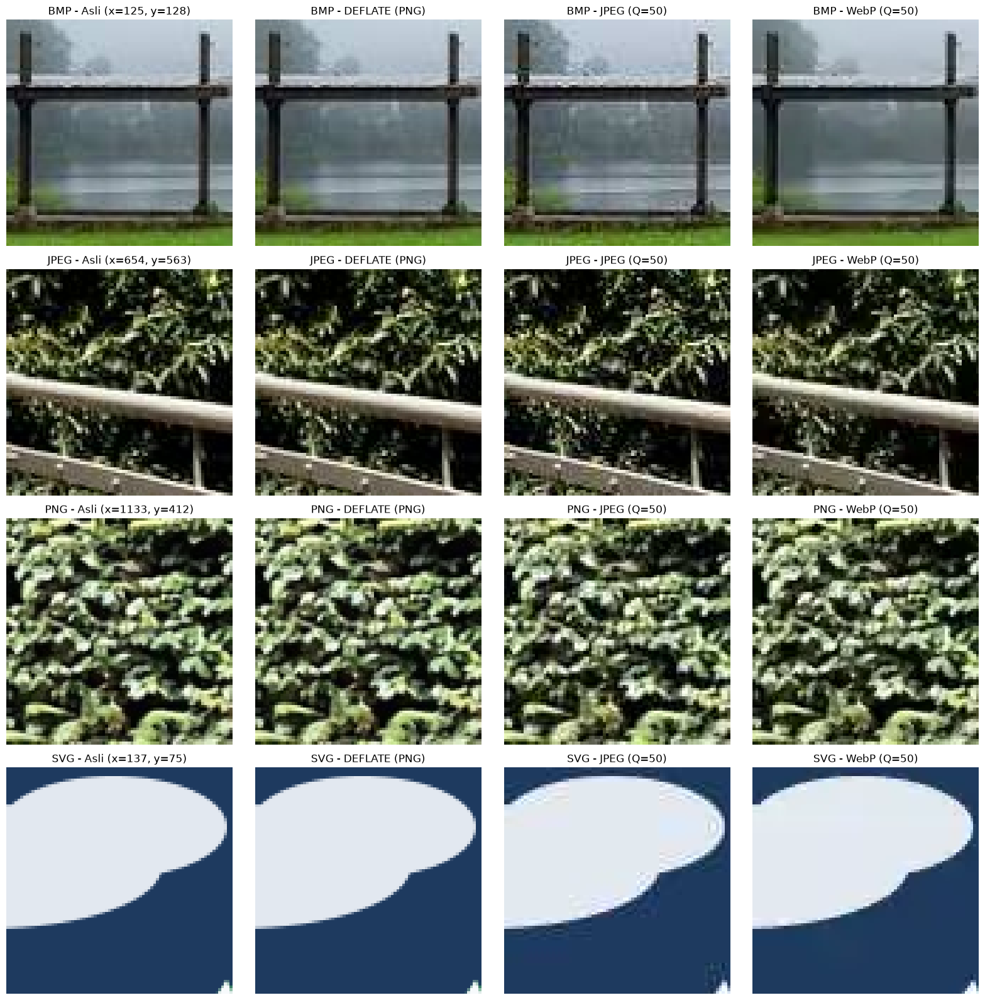

In [11]:
# Perbandingan visual: citra asli vs hasil rekonstruksi 3 teknik, lalu zoom 80x80 piksel untuk melihat artefak
nama_teknik_list = [t[0] for t in TEKNIK_KOMPRESI]
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for i, (nama_citra, data) in enumerate(citra.items()):
    kolom = [data["arr"]] + [rekonstruksi[(nama_citra, t)] for t in nama_teknik_list]
    judul = ["Asli"] + nama_teknik_list
    for j, img in enumerate(kolom):
        axes[i, j].imshow(img)
        axes[i, j].axis("off")
        axes[i, j].set_title(f"{nama_citra} - {judul[j]}")
plt.tight_layout()
plt.savefig(KOMP_DIR / "visual_kompresi.png", dpi=100)
plt.show()

# Zoom 80x80 piksel di area dengan tepi paling kuat (gradien Sobel setelah blur) pada citra asli
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for i, (nama_citra, data) in enumerate(citra.items()):
    abu = cv2.GaussianBlur(cv2.cvtColor(data["arr"], cv2.COLOR_RGB2GRAY), (0, 0), 2)
    gx = cv2.Sobel(abu, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(abu, cv2.CV_32F, 0, 1)
    tepi = cv2.boxFilter(np.hypot(gx, gy), -1, (80, 80), normalize=False)
    y, x = np.unravel_index(np.argmax(tepi), tepi.shape)
    y0 = min(max(y - 40, 0), abu.shape[0] - 80)
    x0 = min(max(x - 40, 0), abu.shape[1] - 80)
    kolom = [data["arr"]] + [rekonstruksi[(nama_citra, t)] for t in nama_teknik_list]
    judul = ["Asli"] + nama_teknik_list
    for j, img in enumerate(kolom):
        axes[i, j].imshow(img[y0:y0 + 80, x0:x0 + 80], interpolation="nearest")
        axes[i, j].axis("off")
        axes[i, j].set_title(f"{nama_citra} - {judul[j]}" + (f" (x={x0}, y={y0})" if j == 0 else ""))
plt.tight_layout()
plt.savefig(KOMP_DIR / "visual_kompresi_zoom.png", dpi=100)
plt.show()

# Soal 5: Watermarking dengan 2 Teknik

In [12]:
# Siapkan citra host (gambar asli) dan watermark biner berupa teks di area yang lebih gelap, dipakai untuk visible dan LSB
host = cv2.resize(frames[0], (512, 512))
wm = np.zeros((512, 512), np.uint8)
wm = cv2.putText(wm, "105224041", (50, 480), cv2.FONT_HERSHEY_SIMPLEX, 2.0, 1, 4)

In [13]:
# Fungsi watermark: visible (alpha blending), LSB (sisip), dan ekstraksi LSB
def embed_visible(host, wm, alpha=0.5):
    # Campur piksel host dengan putih (255) hanya di tempat teks watermark
    host_f = host.astype(np.float32)
    hasil = np.where(wm[:, :, None] == 1, (1 - alpha) * host_f + alpha * 255, host_f)
    return np.clip(hasil, 0, 255).astype(np.uint8)


def embed_lsb(host, wm):
    # Ganti bit paling akhir (LSB) kanal R dengan bit watermark
    hasil = host.copy()
    hasil[:, :, 0] = (hasil[:, :, 0] & 0xFE) | wm
    return hasil


def extract_lsb(img):
    # Ambil kembali LSB kanal R
    return img[:, :, 0] & 1

In [14]:
# Sisipkan kedua watermark (simpan PNG, bukan JPEG) lalu hitung PSNR dan SSIM terhadap host
img_visible = embed_visible(host, wm)
img_lsb = embed_lsb(host, wm)
for nama, img in (("visible", img_visible), ("lsb", img_lsb)):
    cv2.imwrite(str(WM_DIR / f"watermark_{nama}.png"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    print(f"{nama}: PSNR = {psnr(host, img, data_range=255):.2f} dB, SSIM = {ssim(host, img, data_range=255, channel_axis=2):.4f}")

visible: PSNR = 24.13 dB, SSIM = 0.9578
lsb: PSNR = 55.82 dB, SSIM = 0.9992


In [15]:
# Ekstraksi LSB dan uji ketahanan: serang kedua citra dengan JPEG Q=75, lalu hitung BER
diserang = {}
for nama, img in (("visible", img_visible), ("lsb", img_lsb)):
    _, buf = cv2.imencode(".jpg", cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 75])
    diserang[nama] = cv2.cvtColor(cv2.imdecode(buf, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)

# LSB: ekstrak sebelum dan sesudah serangan, BER (%) = persen bit yang salah
lsb_normal = extract_lsb(img_lsb)
lsb_jpeg = extract_lsb(diserang["lsb"])
ber_lsb_normal = np.mean(wm != lsb_normal) * 100
ber_lsb_jpeg = np.mean(wm != lsb_jpeg) * 100

# Visible: watermark dipulihkan dari selisih abu-abu terhadap host (ambang 20)
abu_serang = cv2.cvtColor(diserang["visible"], cv2.COLOR_RGB2GRAY).astype(np.int16)
abu_host = cv2.cvtColor(host, cv2.COLOR_RGB2GRAY).astype(np.int16)
visible_jpeg = (np.abs(abu_serang - abu_host) > 20).astype(np.uint8)
ber_visible_jpeg = np.mean(wm != visible_jpeg) * 100

# Visible tanpa serangan: cara pemulihan sama, pada citra visible sebelum diserang
abu_visible = cv2.cvtColor(img_visible, cv2.COLOR_RGB2GRAY).astype(np.int16)
visible_normal = (np.abs(abu_visible - abu_host) > 20).astype(np.uint8)
ber_visible_normal = np.mean(wm != visible_normal) * 100

print(f"BER LSB normal          : {ber_lsb_normal:.2f}%")
print(f"BER LSB setelah JPEG    : {ber_lsb_jpeg:.2f}%")
print(f"BER visible tanpa serangan: {ber_visible_normal:.2f}% | setelah JPEG: {ber_visible_jpeg:.2f}%")

BER LSB normal          : 0.00%
BER LSB setelah JPEG    : 49.57%
BER visible tanpa serangan: 0.00% | setelah JPEG: 0.04%


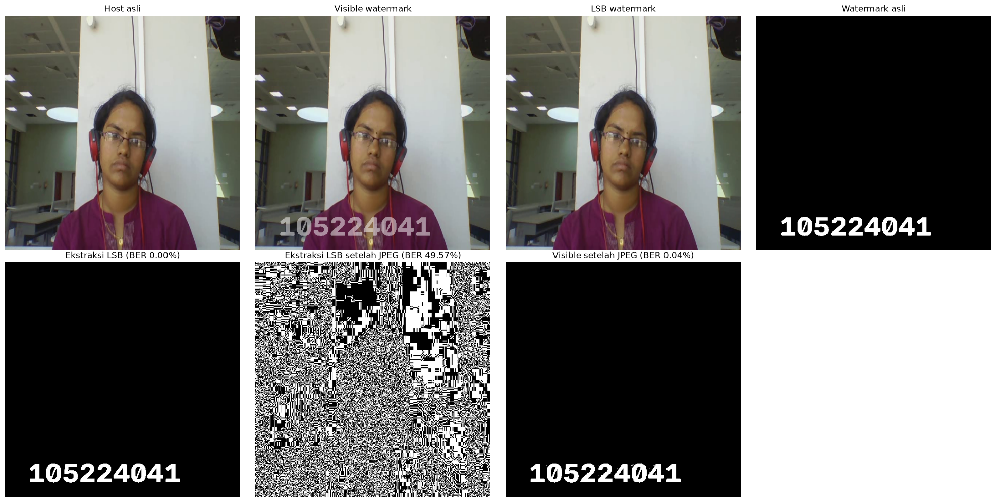

In [16]:
# Tampilkan citra sebelum dan sesudah watermark, serta hasil ekstraksi
gambar = [
    (host, "Host asli"),
    (img_visible, "Visible watermark"),
    (img_lsb, "LSB watermark"),
    (wm * 255, "Watermark asli"),
    (lsb_normal * 255, f"Ekstraksi LSB (BER {ber_lsb_normal:.2f}%)"),
    (lsb_jpeg * 255, f"Ekstraksi LSB setelah JPEG (BER {ber_lsb_jpeg:.2f}%)"),
    (visible_jpeg * 255, f"Visible setelah JPEG (BER {ber_visible_jpeg:.2f}%)"),
]
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax in axes.ravel():
    ax.axis("off")
for ax, (img, judul) in zip(axes.ravel(), gambar):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(judul)
plt.tight_layout()
plt.savefig(WM_DIR / "evaluasi_watermarking.png", dpi=100)
plt.show()